# Baseline run: DePlot on the validation sample

**Goal:** get a first, untuned score for the pipeline, so later improvements have something to be compared against.

```
chart image -> DePlot (or UniChart) -> table -> LLM + question -> answer -> compare with label
```

| Step | Status |
|---|---|
| Look at the data | done |
| Make a shared stratified validation sample (300 rows) | done |
| Run DePlot on the sample (Kaggle GPU) | done |
| Run UniChart on the same sample (teammate) | in progress |
| LLM answers from the tables | next |
| Proper scoring (relaxed accuracy) | next |

## 1. The data

ChartQA, from `datasets/HuggingFaceM4/ChartQA/data/`. Each row is one *question* about a chart.

| Split | Rows | Files |
|---|---|---|
| train | 28,299 | 3 shards of 9,433 |
| validation | 1,920 | 1 |
| test | 2,500 | 1 |

The baseline uses **validation**. The test set is kept for one final run.

In [1]:
import hashlib
from pathlib import Path

import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "data_exploration" else Path.cwd()
VAL = ROOT / "datasets/HuggingFaceM4/ChartQA/data/val-00000-of-00001-0f11003c77497969.parquet"

val = pd.read_parquet(VAL)
chart_id = val["image"].apply(lambda d: hashlib.md5(d["bytes"]).hexdigest())

print("validation rows:", len(val))
print("unique charts:  ", chart_id.nunique(), "(several questions share one chart)")
print()
print(val["human_or_machine"].value_counts().sort_index().to_string())

validation rows: 1920
unique charts:   1055 (several questions share one chart)

human_or_machine
0    960
1    960


## 2. The shared stratified sample

- Made by `utils/make_val_sample.py`, saved as `results/val_sample_300.csv`.
- **Stratified** on `human_or_machine`: the validation set is 50/50, so the sample is 150 + 150.
- Both DePlot and UniChart runs use this exact file, so the two scores can be compared fairly.
- The file stores `row_idx`, the row's position in the validation parquet, so the image can be fetched again.
- Do not re-run the script to make a new sample. Everyone loads the saved CSV.

In [2]:
sample = pd.read_csv(ROOT / "results/val_sample_300.csv")

print("sample rows:    ", len(sample))
print("unique charts:  ", chart_id.iloc[sample["row_idx"]].nunique())
print()
print(sample["human_or_machine"].value_counts().sort_index().to_string())
sample.head()

sample rows:     300
unique charts:   279

human_or_machine
0    150
1    150


,row_idx,query,label,human_or_machine
0,23,IS the value of No more then sum of Yes and Dk?,Yes,0
1,30,What's the value of leftmost bar in the bottom?,12,0
2,39,What is the difference between the longest and...,7,0
3,44,What's the value of United States?,0.124,0
4,59,Find the average of the percentage value of ba...,1.608,0


## 3. Running DePlot on Kaggle

Script: `utils/run_deplot.py`. It reads the sample, runs DePlot once per unique chart, and saves one JSON line per row.
It can be stopped and re-run: rows already in the output file are skipped.

Kaggle setup:
- Private dataset `validation-set` holding the validation parquet, `val_sample_300.csv` and `run_deplot.py`
- Notebook settings: GPU on, Internet on
- A 5-row test first (`--limit 5`), then the full run

Run details:
- GPU used: Kaggle GPU (T4)
- Rows / unique charts: 300 / 279 (DePlot ran once per chart)
- Total DePlot time: about 34 minutes (sum of per-chart times; the whole Kaggle session ran about 38 minutes)
- Seconds per chart: mean 7.27, median 4.63, min 1.06, max 34.94
- Empty tables: 0

## 4. Results

In [3]:
RESULTS = ROOT / "results/deplot_val_300.jsonl"

if RESULTS.exists():
    deplot = pd.read_json(RESULTS, lines=True)
    print("rows:", len(deplot), "| unique charts:", deplot["chart_hash"].nunique())
else:
    deplot = None
    print(f"{RESULTS.name} not found yet. Download it from the Kaggle output and put it in results/.")

rows: 300 | unique charts: 279


In [4]:
if deplot is not None:
    per_chart = deplot.drop_duplicates("chart_hash")["deplot_s"]
    print(f"seconds per chart: mean {per_chart.mean():.2f}, median {per_chart.median():.2f}, max {per_chart.max():.2f}")
    print(f"total GPU time:    {per_chart.sum() / 60:.1f} minutes")
    empty = (deplot["deplot_table"].str.strip() == "").sum()
    print(f"rows with an empty table: {empty}")

seconds per chart: mean 7.27, median 4.63, max 34.94
total GPU time:    33.8 minutes
rows with an empty table: 0


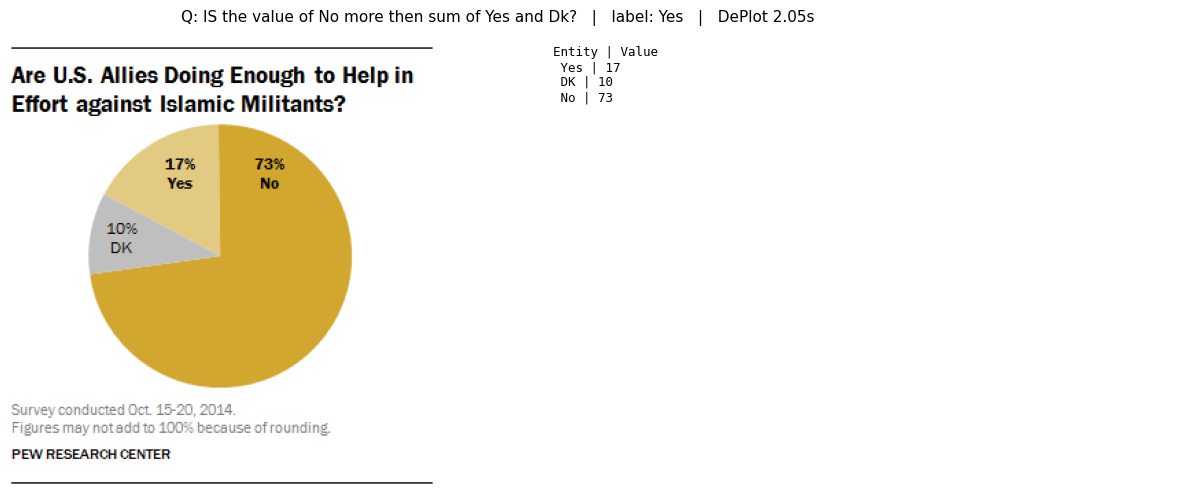

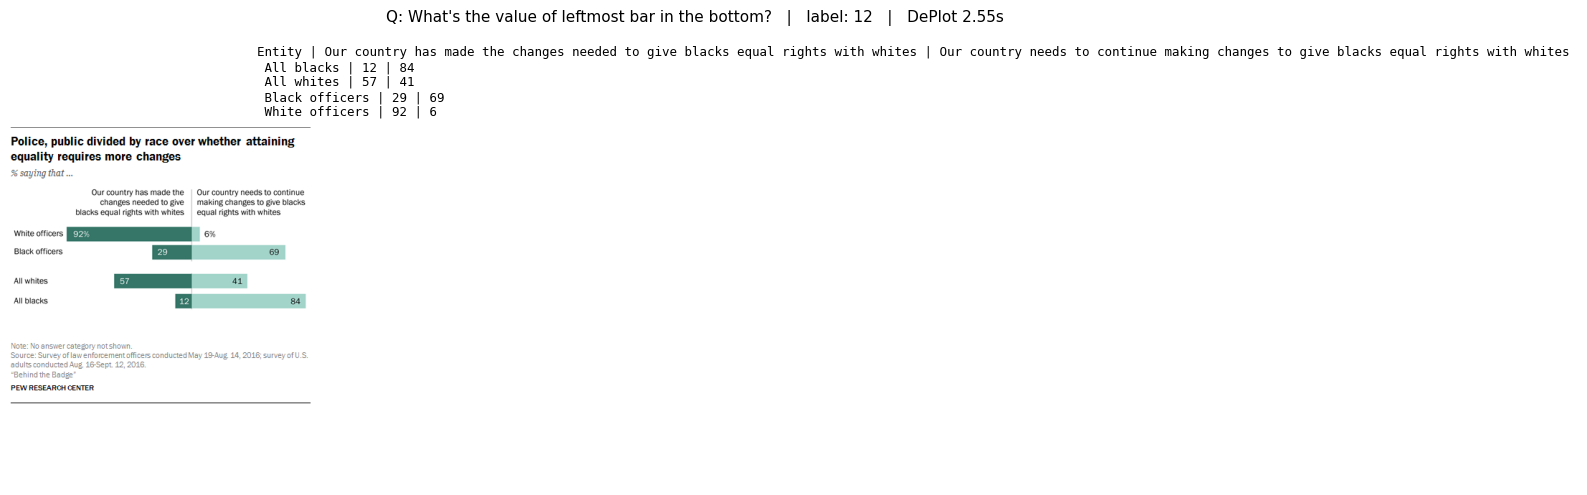

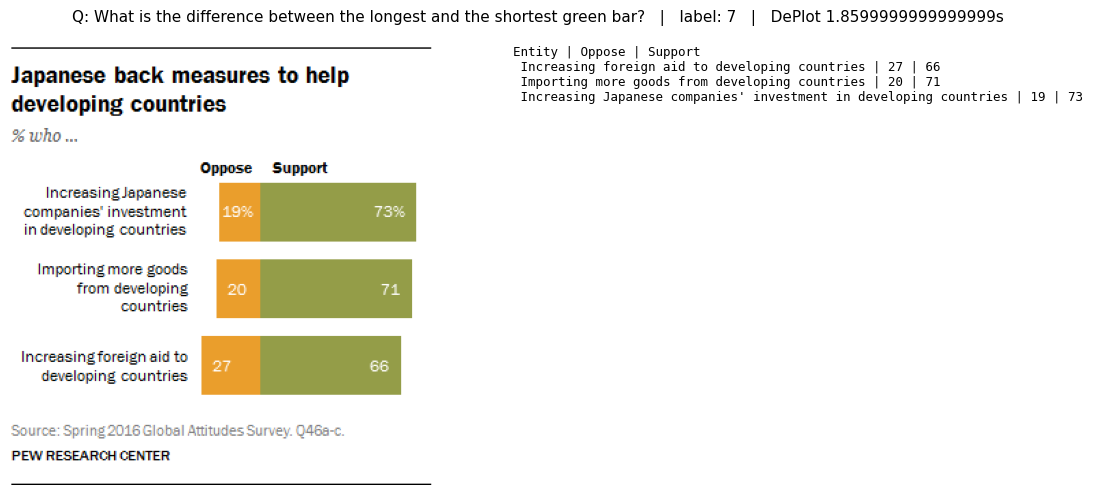

In [5]:
import io

import matplotlib.pyplot as plt
from PIL import Image

N_SHOW = 3  # change to look at more

if deplot is not None:
    for _, r in deplot.head(N_SHOW).iterrows():
        img = Image.open(io.BytesIO(val.iloc[r["row_idx"]]["image"]["bytes"])).convert("RGB")
        fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.3, 1]})
        a.imshow(img)
        a.axis("off")
        b.text(0, 1, r["deplot_table"], va="top", family="monospace", fontsize=9)
        b.axis("off")
        fig.suptitle(f"Q: {r['query']}   |   label: {r['label']}   |   DePlot {r['deplot_s']}s", fontsize=11)
        plt.tight_layout()
        plt.show()

## 5. Observations

Fill in after looking at the tables:
- What DePlot reads well:
- Where it goes wrong (missing values, invented values, shifted rows):
- Differences between human-written and machine-generated questions:

## 6. Next steps

1. Pass each table and its question to an LLM (DeepSeek is already set up in `.env`) and get an answer.
2. Score with ChartQA relaxed accuracy: numbers within 5% of the label, text must match exactly.
3. Compare with the teammate's UniChart results on the same 300 rows.
4. Report accuracy overall and split by `human_or_machine`.
5. Later: fine-tune on train, check on validation, and run the test set once at the end.